# Notebook 3: Model Evaluation and Insights

**Project:** Luxury Watch Resale Price Analysis (final capstone)
**Author:** Mina Andrawos

Notebook 2 selected a tuned Gradient Boosting model. This notebook evaluates it in depth on the hold-out test set and turns it into business insights: where it is reliable, which features drive its predictions, and how much specific features (condition, case material, age, size) are worth.

| # | Notebook | Purpose |
|---|---|---|
| 1 | [Data cleaning and EDA](01_data_cleaning_and_eda.ipynb) | Clean both datasets, engineer features, explore price drivers |
| 2 | [Model training and tuning](02_model_training_and_tuning.ipynb) | Compare five model types with cross-validation and grid search |
| **3** | **Model evaluation and insights (this notebook)** | Test-set results, error analysis, feature importance, price premiums |
| 4 | [Box, papers and seller analysis](04_box_papers_and_seller_analysis.ipynb) | Measure the value of box, papers and seller reputation |

### Notebook outline
1. Setup: load the model and recreate the test set
2. Test-set performance and comparison with the initial baseline
3. Actual vs predicted prices
4. Where does the model make mistakes? (price tier and brand)
5. Which features drive the predictions? (permutation importance)
6. How do age and size affect price? (partial dependence)
7. What is a feature worth? (what-if premiums for condition and case material)
8. Practical use: flagging under- and over-priced listings
9. Summary

## 1. Setup

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from matplotlib.ticker import FuncFormatter
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid", context="notebook")
dollar_format = FuncFormatter(lambda value, _: f"${value:,.0f}")
percent_change_format = FuncFormatter(lambda value, _: f"{value:+.0%}")

MODELS_DIR = Path("models")
IMAGES_DIR = Path("images")

with open(MODELS_DIR / "model_settings.json") as settings_file:
    settings = json.load(settings_file)
price_model = joblib.load(MODELS_DIR / "price_model_pipeline.joblib")
test_results = pd.read_csv(MODELS_DIR / "test_results.csv", index_col="Model")

# Recreate exactly the same train/test split as Notebook 2 (same data, test size and random seed)
listings = pd.read_parquet("data/processed/listings_clean.parquet")
train_df, test_df = train_test_split(listings, test_size=settings["test_size"], random_state=settings["random_state"])
FEATURES, TARGET = settings["features"], settings["target"]
X_test, y_test = test_df[FEATURES], test_df[TARGET]

test_df = test_df.assign(predicted_log=price_model.predict(X_test))
test_df["predicted_price"] = 10 ** test_df["predicted_log"]
test_df["residual"] = test_df[TARGET] - test_df["predicted_log"]   # > 0: listed above the model's estimate
test_df["abs_pct_error"] = (test_df["predicted_price"] - test_df["price"]).abs() / test_df["price"]

print(f"Selected model: {settings['selected_model']} | feature set: {settings['feature_set']}")
print(f"Test listings: {len(test_df):,}")

Selected model: Gradient Boosting | feature set: C: + Model line
Test listings: 52,130


## 2. Test-Set Performance
Primary metric: **RMSE on log10 price** (lower is better; penalizes large relative mispricings). Supporting metrics: R² on log price, median absolute percentage error (MdAPE) and the share of predictions within ±25% of the listed price. See Notebook 2, section 2, for the rationale.

In [2]:
display(test_results.drop(columns="Fit time (s)").style.format({
    "RMSE (log10)": "{:.3f}", "R² (log)": "{:.3f}", "MAE (log10)": "{:.3f}", "MdAPE": "{:.1%}",
    "Within ±25%": "{:.1%}", "Median abs error (USD)": "${:,.0f}", "Error factor": "{:.2f}x"}))

# Comparison with the initial report (Ridge on Dataset 2, from the initial capstone README)
selected = test_results.loc[settings["selected_model"]]
progress = pd.DataFrame({
    "Initial report: Ridge baseline (Dataset 2)": {"R² (log)": 0.80, "RMSE (log10)": 0.31, "MdAPE": 0.37},
    f"Final: {settings['selected_model']} (Dataset 1)": selected[["R² (log)", "RMSE (log10)", "MdAPE"]],
}).T
display(progress.style.format({"R² (log)": "{:.2f}", "RMSE (log10)": "{:.2f}", "MdAPE": "{:.0%}"}))

,RMSE (log10),R² (log),MAE (log10),MdAPE,Within ±25%,Median abs error (USD),Error factor
Model,,,,,,,
Gradient Boosting,0.184,0.905,0.126,20.1%,58.5%,"$1,173",1.53x
Random Forest,0.184,0.904,0.125,19.6%,59.2%,"$1,149",1.53x
Ridge,0.225,0.857,0.159,26.3%,48.0%,"$1,520",1.68x
Lasso,0.226,0.856,0.160,26.5%,47.8%,"$1,528",1.68x
Dummy (mean),0.595,-0.000,0.460,69.5%,17.0%,"$4,830",3.93x


,R² (log),RMSE (log10),MdAPE
Initial report: Ridge baseline (Dataset 2),0.80,0.31,37%
Final: Gradient Boosting (Dataset 1),0.90,0.18,20%


**Interpretation:** On 52,000 listings it has never seen, the Gradient Boosting model explains **90.5% of the variation in log price (R²)**, with a typical error factor of 1.53x and a **median error of 20%**. Random Forest is practically tied; Ridge (26%) and the dummy benchmark (70%) are clearly worse.

**Progress since the initial report:** the median error fell from **37% to 20%** and R² rose from **0.80 to 0.90**. Part of this comes from the better model and part from the richer Dataset 1 (model names). Notebook 4 makes a like-for-like comparison on Dataset 2: with the same features, Gradient Boosting alone cuts the baseline's median error from about 39% to 35%, and adding the extra Dataset 2 features brings it to 29%.

## 3. Actual vs Predicted Prices

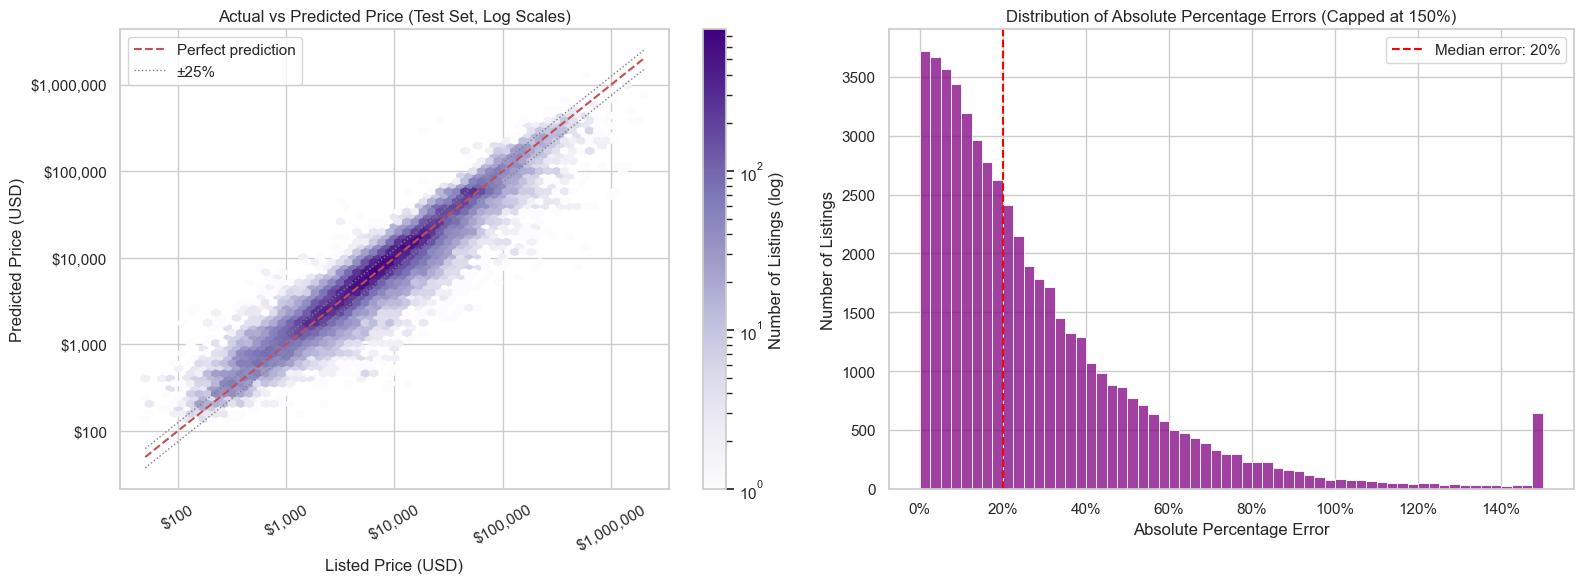

Predictions within ±10% of the listed price: 27.6%
Predictions within ±25% of the listed price: 58.5%
Predictions within ±50% of the listed price: 83.9%
Errors above 150%: 1.2% of listings
  errors above 150%: generic/missing model line 57%, unknown case material 90%, unknown year 49%
  all test listings: generic/missing model line 12%, unknown case material 58%, unknown year 33%


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

hexbin = axes[0].hexbin(test_df["price"], test_df["predicted_price"], xscale="log", yscale="log",
                        gridsize=60, cmap="Purples", bins="log", mincnt=1)
price_range = [test_df["price"].min(), test_df["price"].max()]
axes[0].plot(price_range, price_range, "r--", lw=1.5, label="Perfect prediction")
axes[0].plot(price_range, [p * 1.25 for p in price_range], color="gray", lw=1, ls=":", label="±25%")
axes[0].plot(price_range, [p * 0.75 for p in price_range], color="gray", lw=1, ls=":")
axes[0].xaxis.set_major_formatter(dollar_format)
axes[0].yaxis.set_major_formatter(dollar_format)
axes[0].tick_params(axis="x", rotation=30)
axes[0].set_title("Actual vs Predicted Price (Test Set, Log Scales)")
axes[0].set_xlabel("Listed Price (USD)")
axes[0].set_ylabel("Predicted Price (USD)")
axes[0].legend(loc="upper left")
fig.colorbar(hexbin, ax=axes[0], label="Number of Listings (log)")

sns.histplot(test_df["abs_pct_error"].clip(upper=1.5), bins=60, color="purple", ax=axes[1])
axes[1].axvline(test_df["abs_pct_error"].median(), color="red", ls="--",
                label=f"Median error: {test_df['abs_pct_error'].median():.0%}")
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].set_title("Distribution of Absolute Percentage Errors (Capped at 150%)")
axes[1].set_xlabel("Absolute Percentage Error")
axes[1].set_ylabel("Number of Listings")
axes[1].legend()

plt.tight_layout()
plt.savefig(IMAGES_DIR / "actual_vs_predicted.png", dpi=110, bbox_inches="tight")
plt.show()

for threshold in [0.10, 0.25, 0.50]:
    print(f"Predictions within ±{threshold:.0%} of the listed price: {(test_df['abs_pct_error'] <= threshold).mean():.1%}")

# How often is information missing for the worst predictions, compared with all test listings?
test_df["generic_model"] = test_df["model_line"].str.endswith(("| Other", "| Unknown"))
worst = test_df["abs_pct_error"] > 1.5
print(f"Errors above 150%: {worst.mean():.1%} of listings")
for label, subset in [("errors above 150%", test_df[worst]), ("all test listings", test_df)]:
    print(f"  {label}: generic/missing model line {subset['generic_model'].mean():.0%}, "
          f"unknown case material {(subset['case_material'] == 'Unknown').mean():.0%}, "
          f"unknown year {subset['year'].isna().mean():.0%}")

**Observation:** Predictions follow the diagonal across the full price range, from under USD 100 to about USD 2 million. **28% of predictions are within ±10% of the listed price, 59% within ±25% and 84% within ±50%.** The error distribution has a long right tail: a small share of listings (about 1%, the bar at 150%) are off by more than 150%. These listings are much more often missing information than the average listing (see the printout above): for example, 57% have a generic or missing model line, against 12% of all test listings.

## 4. Where Does the Model Make Mistakes?
The initial Ridge baseline over-predicted cheap watches and under-predicted expensive ones. The cells below check whether the new model has the same bias, and how accurate it is for each brand.

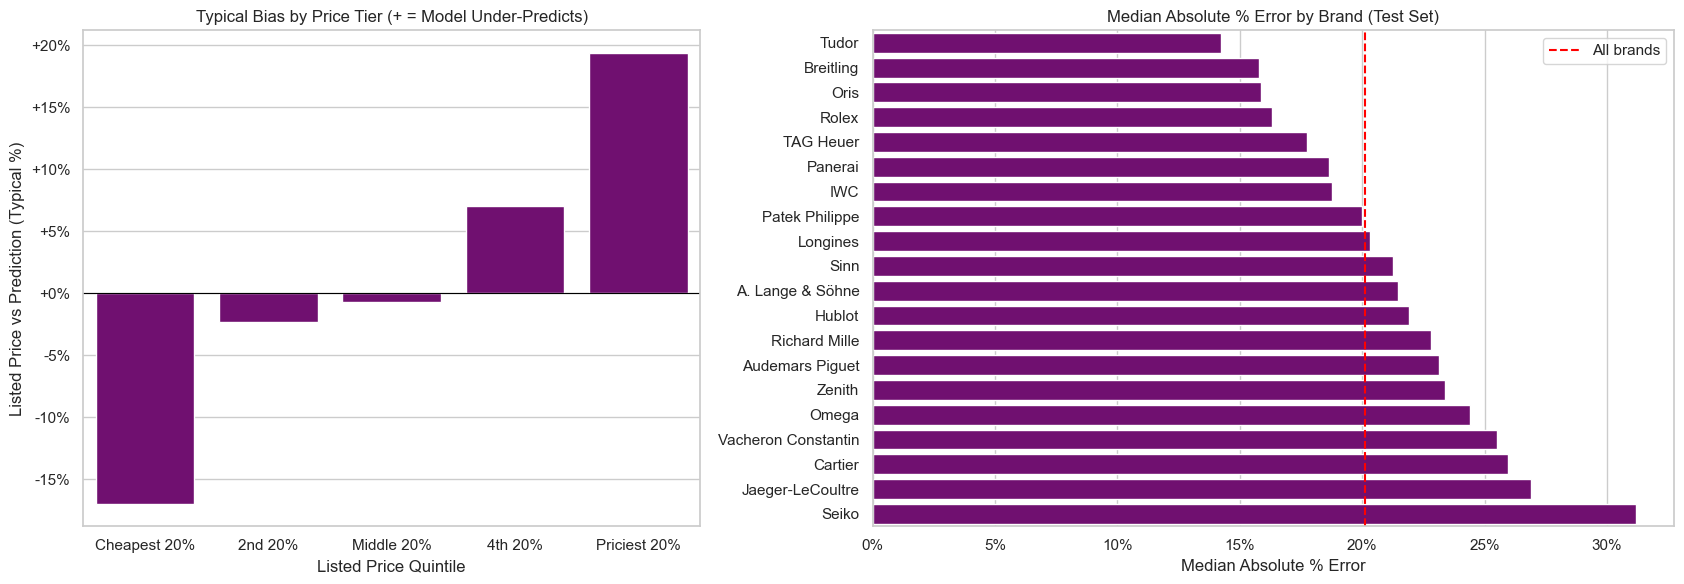

,price_range,mean_residual,median_pct_error,typical bias
price_quintile,,,,
Cheapest 20%,"$50 - $2,307",-0.081,27.1%,-17.0%
2nd 20%,"$2,308 - $5,100",-0.010,19.7%,-2.3%
Middle 20%,"$5,102 - $9,344",-0.003,16.8%,-0.7%
4th 20%,"$9,346 - $19,495",+0.030,17.1%,+7.0%
Priciest 20%,"$19,496 - $2,000,000",+0.077,22.3%,+19.4%


Spearman correlation between a brand's share of generic/missing model lines and its median % error: 0.40
Spearman correlation between a brand's median price and its median % error: 0.16


In [4]:
test_df["price_quintile"] = pd.qcut(test_df["price"], q=5,
                                    labels=["Cheapest 20%", "2nd 20%", "Middle 20%", "4th 20%", "Priciest 20%"])
by_tier = test_df.groupby("price_quintile", observed=True).agg(
    price_range=("price", lambda p: f"${p.min():,.0f} - ${p.max():,.0f}"),
    mean_residual=("residual", "mean"),
    median_pct_error=("abs_pct_error", "median"),
)
# A mean residual in log10 units translates into a typical % bias: 10 ** residual - 1
by_tier["typical bias"] = 10 ** by_tier["mean_residual"] - 1

by_brand = (test_df.groupby("brand")
            .agg(median_pct_error=("abs_pct_error", "median"), listings=("price", "size"),
                 median_price=("price", "median"))
            .sort_values("median_pct_error"))

fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 1.3]})
sns.barplot(x=by_tier.index, y=by_tier["typical bias"], color="purple", ax=axes[0])
axes[0].axhline(0, color="black", lw=0.8)
axes[0].yaxis.set_major_formatter(percent_change_format)
axes[0].set_title("Typical Bias by Price Tier (+ = Model Under-Predicts)")
axes[0].set_xlabel("Listed Price Quintile")
axes[0].set_ylabel("Listed Price vs Prediction (Typical %)")

sns.barplot(x=by_brand["median_pct_error"], y=by_brand.index, color="purple", ax=axes[1])
axes[1].axvline(test_df["abs_pct_error"].median(), color="red", ls="--", label="All brands")
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].set_title("Median Absolute % Error by Brand (Test Set)")
axes[1].set_xlabel("Median Absolute % Error")
axes[1].set_ylabel("")
axes[1].legend()

plt.tight_layout()
plt.show()

display(by_tier.style.format({"mean_residual": "{:+.3f}", "median_pct_error": "{:.1%}", "typical bias": "{:+.1%}"}))
by_brand["generic_model_share"] = test_df.groupby("brand")["generic_model"].mean()
print("Spearman correlation between a brand's share of generic/missing model lines and its median % error: "
      f"{by_brand['generic_model_share'].corr(by_brand['median_pct_error'], method='spearman'):.2f}")
print("Spearman correlation between a brand's median price and its median % error: "
      f"{by_brand['median_price'].corr(by_brand['median_pct_error'], method='spearman'):.2f}")

**Observation:** 
- **The model still pulls extreme prices toward the middle**, like the initial baseline: the cheapest 20% of listings are typically listed about 17% *below* their estimate (the model over-predicts them) and the most expensive 20% about 19% *above* it (the model under-predicts them), while the middle 60% are nearly unbiased (within ±7%). This is typical of regression models: at the extremes, part of what makes a watch unusually cheap or expensive is not captured by the features (for example dial variants, provenance or damage, which are not recorded). **For the most expensive watches, the model's estimate tends to be on the low side.**
- **Accuracy differs by brand** from about 14% median error (Tudor) and 16% (Rolex) to about 31% (Seiko). It is only weakly related to how expensive a brand is (Spearman 0.16). One factor appears to be **how well the model names describe the watches**: brands with a larger share of generic or missing model lines tend to have larger errors (Spearman 0.40 across the 20 brands, printed above). For example, only 1% of Rolex listings have a generic or missing model line, against about a third of Seiko, Jaeger-LeCoultre and Vacheron Constantin listings.

## 5. Which Features Drive the Predictions?
**Permutation importance** shuffles one original feature at a time on test data (5 repeats, on a 20,000-listing sample to keep run time reasonable) and measures how much the RMSE increases. Unlike tree "split counts", it measures how much the *predictions* actually depend on the feature, and it works on the original features rather than the encoded columns.

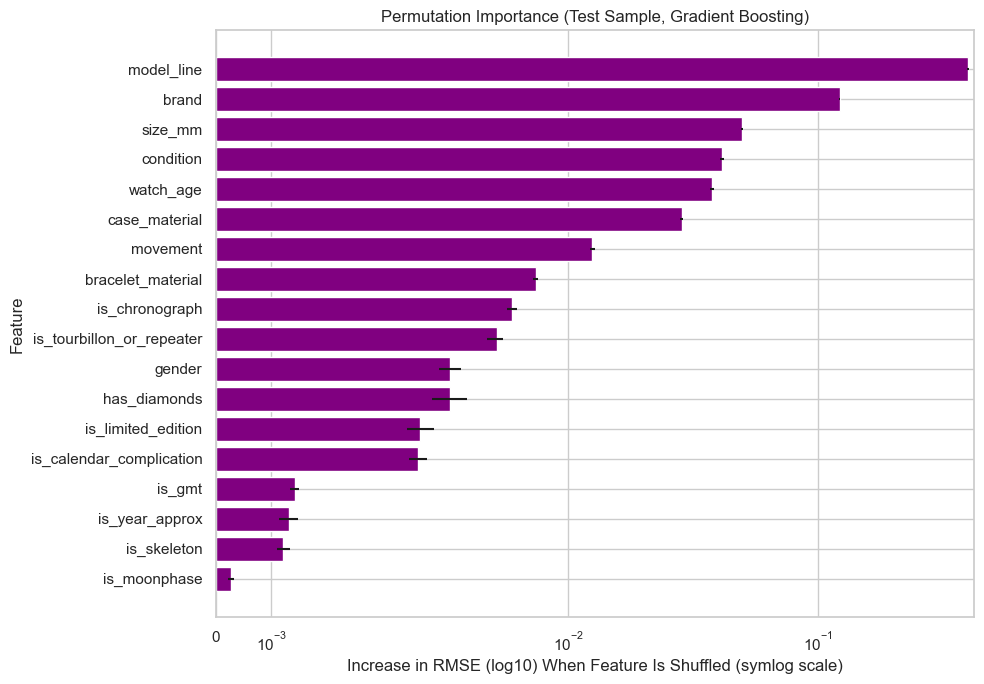

Feature,RMSE increase,Std
model_line,0.3988,0.0026
brand,0.1220,0.0007
size_mm,0.0498,0.0004
condition,0.0414,0.0007
watch_age,0.0376,0.0008
case_material,0.0285,0.0004
movement,0.0125,0.0003
bracelet_material,0.0074,0.0002
is_chronograph,0.0060,0.0003
is_tourbillon_or_repeater,0.0052,0.0003


In [5]:
importance_sample = test_df.sample(n=20_000, random_state=settings["random_state"])
importance = permutation_importance(price_model, importance_sample[FEATURES], importance_sample[TARGET],
                                    n_repeats=5, scoring="neg_root_mean_squared_error",
                                    random_state=settings["random_state"], n_jobs=-1)
importance_df = (pd.DataFrame({"Feature": FEATURES, "RMSE increase": importance.importances_mean,
                               "Std": importance.importances_std})
                 .sort_values("RMSE increase", ascending=False))

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(importance_df["Feature"], importance_df["RMSE increase"], xerr=importance_df["Std"], color="purple")
ax.invert_yaxis()
ax.set_xscale("symlog", linthresh=0.005)   # keeps small importances visible next to the largest ones
ax.set_title("Permutation Importance (Test Sample, Gradient Boosting)")
ax.set_xlabel("Increase in RMSE (log10) When Feature Is Shuffled (symlog scale)")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

display(importance_df.style.format({"RMSE increase": "{:.4f}", "Std": "{:.4f}"}).hide(axis="index"))

**Observation:** 
- **Model line is by far the most important feature**: shuffling it raises RMSE by about 0.40, roughly tripling the error (from 0.18 to about 0.58). **Brand** is second (0.12). Brand looks less important than in the initial report largely because the model line already contains much of the brand information.
- Next come **case size, condition, watch age and case material** (0.03-0.05 each), then movement and bracelet material.
- The **complication and text flags** add little *on top of the model line* (each under 0.01), likely because the model line already tells the model that, say, a Daytona is a chronograph.

## 6. How Do Age and Case Size Affect Price?
**Partial dependence:** for a sample of 5,000 test listings, the model predicts the price again with the age (or case size) set to each value on a grid, keeping every other feature unchanged. The median change, relative to a reference value, shows the effect of that feature alone as the model sees it.

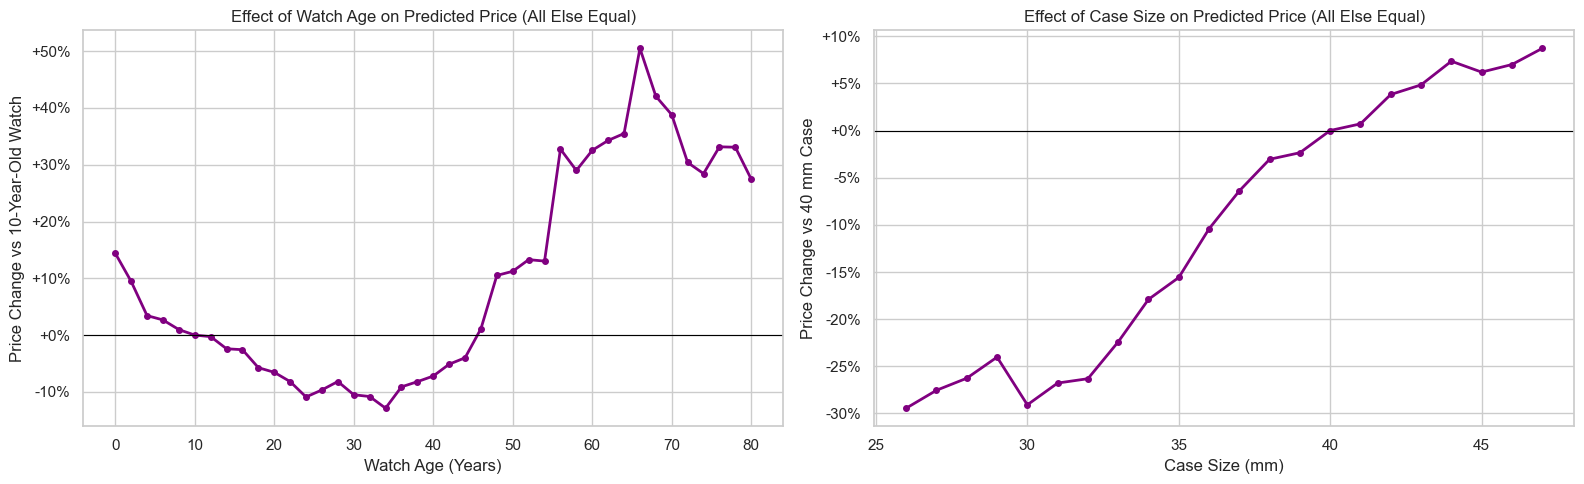

Lowest point of the age curve: -13% at 34 years; range for ages 24-34: -13% to -8%; range for ages 56-70: +29% to +50%
Listings 50+ years old: 6.8% of all listings, 10.2% of those with a known year
Age effect at selected ages: 0 yrs +14%, 4 yrs +3%, 20 yrs -7%, 40 yrs -7%, 60 yrs +33%, 80 yrs +27%
Size effect at selected sizes: 28 mm -26%, 34 mm -18%, 38 mm -3%, 42 mm +4%, 46 mm +7%


In [6]:
pd_sample = test_df.sample(n=5_000, random_state=settings["random_state"])


def partial_dependence_curve(feature, grid, reference_value):
    """Median predicted price change vs reference_value as one feature varies, everything else unchanged."""
    reference = price_model.predict(pd_sample[FEATURES].assign(**{feature: reference_value}))
    return pd.Series([np.median(10 ** (price_model.predict(pd_sample[FEATURES].assign(**{feature: value}))
                                       - reference)) - 1 for value in grid], index=grid)


age_curve = partial_dependence_curve("watch_age", np.arange(0, 81, 2), reference_value=10)
size_curve = partial_dependence_curve("size_mm", np.arange(26, 48, 1), reference_value=40)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, curve, label, reference_label in [(axes[0], age_curve, "Watch Age (Years)", "10-Year-Old Watch"),
                                          (axes[1], size_curve, "Case Size (mm)", "40 mm Case")]:
    ax.plot(curve.index, curve.values, marker="o", color="purple", lw=2, ms=4)
    ax.axhline(0, color="black", lw=0.8)
    ax.yaxis.set_major_formatter(percent_change_format)
    ax.set_xlabel(label)
    ax.set_ylabel(f"Price Change vs {reference_label}")
    ax.set_title(f"Effect of {label.split(' (')[0]} on Predicted Price (All Else Equal)")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "age_and_size_effect.png", dpi=110, bbox_inches="tight")
plt.show()

print(f"Lowest point of the age curve: {age_curve.min():+.0%} at {age_curve.idxmin()} years; "
      f"range for ages 24-34: {age_curve.loc[24:34].min():+.0%} to {age_curve.loc[24:34].max():+.0%}; "
      f"range for ages 56-70: {age_curve.loc[56:70].min():+.0%} to {age_curve.loc[56:70].max():+.0%}")
print(f"Listings 50+ years old: {(listings['watch_age'] >= 50).mean():.1%} of all listings, "
      f"{(listings.loc[listings['year'].notna(), 'watch_age'] >= 50).mean():.1%} of those with a known year")
print("Age effect at selected ages: " + ", ".join(f"{age} yrs {age_curve[age]:+.0%}" for age in [0, 4, 20, 40, 60, 80]))
print("Size effect at selected sizes: " + ", ".join(f"{size} mm {size_curve[size]:+.0%}" for size in [28, 34, 38, 42, 46]))

**Observation:** 
- **Age has a U-shaped effect**, which helps explain why the linear age term in the initial report looked useless. Compared with a 10-year-old watch, a brand-new one is predicted about **14% higher**; the value is lowest, about **8-13% below**, for watches 24-34 years old; and it rises again above the 10-year level after about 45 years, reaching about **+30% to +50% for 56-70-year-old vintage pieces**. Only about 7% of all listings (10% of those with a known year) are 50 or more years old, so the vintage part of the curve is less certain.
- **Larger cases are worth more, with smaller gains above 40 mm**: holding everything else fixed, a 28 mm case is predicted about **26% lower** than a 40 mm case, and a 46 mm case about **7% higher**. Most of the change happens between 32 and 40 mm.

## 7. What Is a Feature Worth? Model-Estimated Premiums
Using the same "what-if" approach, the model predicts each test listing's price twice, changing only one feature. To avoid unrealistic combinations (e.g. a platinum version of a model that only exists in steel), the case-material comparison only uses **model lines that exist in both materials** in the training data (at least 5 listings each).

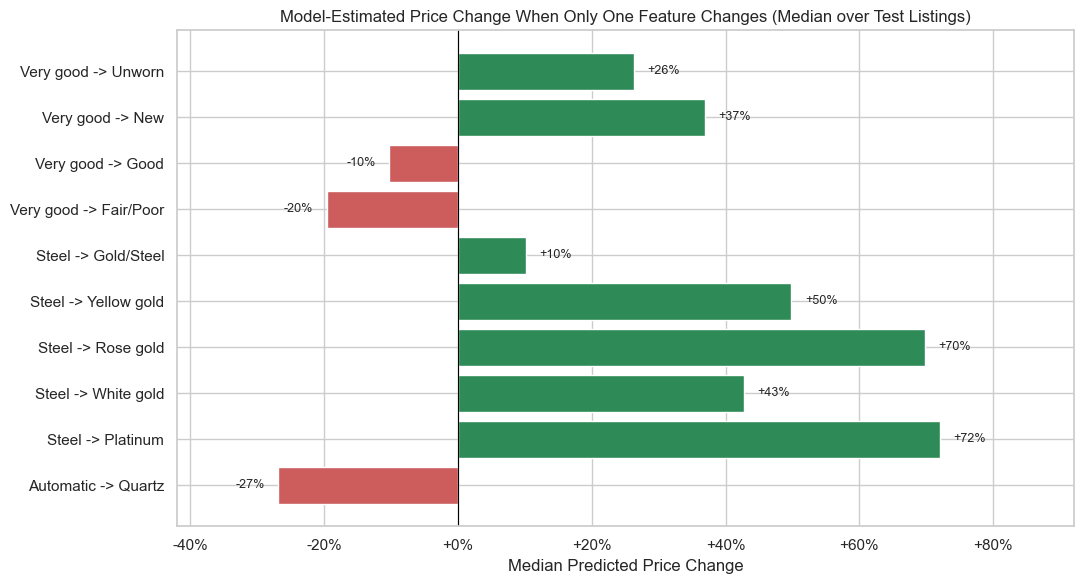

Change,Group,Median premium,Listings
Very good -> Unworn,Condition,+26.2%,"20,307"
Very good -> New,Condition,+36.9%,"20,307"
Very good -> Good,Condition,-10.3%,"20,307"
Very good -> Fair/Poor,Condition,-19.6%,"20,307"
Steel -> Gold/Steel,Case material,+10.1%,"8,291"
Steel -> Yellow gold,Case material,+49.8%,"6,717"
Steel -> Rose gold,Case material,+69.8%,"7,111"
Steel -> White gold,Case material,+42.7%,"3,842"
Steel -> Platinum,Case material,+72.1%,802
Automatic -> Quartz,Movement,-26.9%,"4,160"


In [7]:
def what_if_ratio(data, column, new_value):
    """Predicted price ratio per listing when only `column` is changed to `new_value`."""
    return 10 ** (price_model.predict(data[FEATURES].assign(**{column: new_value}))
                  - price_model.predict(data[FEATURES]))


premium_rows = []

# Condition: start from listings in 'Very good' condition
very_good = test_df[test_df["condition"] == "Very good"]
for new_condition in ["Unworn", "New", "Good", "Fair/Poor"]:
    ratios = what_if_ratio(very_good, "condition", new_condition)
    premium_rows.append({"Change": f"Very good -> {new_condition}", "Group": "Condition",
                         "Median premium": np.median(ratios) - 1, "Listings": len(ratios)})

# Case material: start from steel listings whose model line also exists in the target material
material_counts = train_df.groupby(["model_line", "case_material"]).size()
steel = test_df[test_df["case_material"] == "Steel"]
for new_material in ["Gold/Steel", "Yellow gold", "Rose gold", "White gold", "Platinum"]:
    lines_in_both = [line for line in steel["model_line"].unique()
                     if material_counts.get((line, "Steel"), 0) >= 5 and material_counts.get((line, new_material), 0) >= 5]
    eligible = steel[steel["model_line"].isin(lines_in_both)]
    ratios = what_if_ratio(eligible, "case_material", new_material)
    premium_rows.append({"Change": f"Steel -> {new_material}", "Group": "Case material",
                         "Median premium": np.median(ratios) - 1, "Listings": len(ratios)})

# Movement: automatic -> quartz within model lines that exist in both
movement_counts = train_df.groupby(["model_line", "movement"]).size()
automatic = test_df[test_df["movement"] == "Automatic"]
lines_in_both = [line for line in automatic["model_line"].unique()
                 if movement_counts.get((line, "Automatic"), 0) >= 5 and movement_counts.get((line, "Quartz"), 0) >= 5]
ratios = what_if_ratio(automatic[automatic["model_line"].isin(lines_in_both)], "movement", "Quartz")
premium_rows.append({"Change": "Automatic -> Quartz", "Group": "Movement",
                     "Median premium": np.median(ratios) - 1, "Listings": len(ratios)})

premiums = pd.DataFrame(premium_rows)

fig, ax = plt.subplots(figsize=(11, 6))
colors = premiums["Median premium"].map(lambda v: "seagreen" if v > 0 else "indianred")
ax.barh(premiums["Change"], premiums["Median premium"], color=colors)
for y, (value, n) in enumerate(zip(premiums["Median premium"], premiums["Listings"])):
    ax.text(value + (0.02 if value > 0 else -0.02), y, f"{value:+.0%}", va="center",
            ha="left" if value > 0 else "right", fontsize=9)
ax.invert_yaxis()
ax.axvline(0, color="black", lw=0.8)
ax.xaxis.set_major_formatter(percent_change_format)
ax.set_xlim(premiums["Median premium"].min() - 0.15, premiums["Median premium"].max() + 0.2)
ax.set_title("Model-Estimated Price Change When Only One Feature Changes (Median over Test Listings)")
ax.set_xlabel("Median Predicted Price Change")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "what_if_premiums.png", dpi=110, bbox_inches="tight")
plt.show()

display(premiums.style.format({"Median premium": "{:+.1%}", "Listings": "{:,}"}).hide(axis="index"))

**Observation:** For the same watch (same brand, model line and everything else):
- **Condition:** *New* is worth about **+37%** and *Unworn* about **+26%** compared with *Very good*; *Good* about **-10%** and *Fair/Poor* about **-20%**.
- **Case material:** within model lines that exist in both materials, two-tone gold/steel adds about **+10%**, white gold **+43%**, yellow gold **+50%**, rose gold **+70%** and platinum **+72%** compared with steel.
- **Movement:** a quartz version of the same model line is worth about **27% less** than the automatic one.

These premiums are much smaller than the raw within-brand ratios in Notebook 1 (e.g. platinum about 3x steel), because the raw comparisons also include differences between models (for example, platinum may be used mostly for more expensive models). The model-based estimates are the better guide for comparing two versions of the same watch.

## 8. Practical Use: Flagging Under- and Over-Priced Listings
A marketplace or a buyer can use the model's prediction as a **fair-value estimate** and compare it with the asking price. The cell below shows how test listings are spread around their fair value. Because the typical error is about 20%, only large gaps should be treated as signals worth a closer look, not as proof of a bargain.

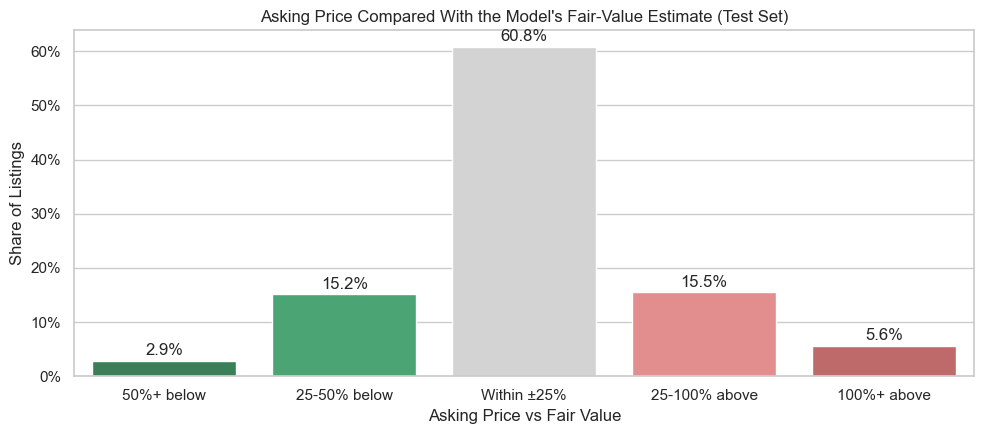

Listings more than 50% below fair value: generic/missing model line 46%, unknown case material 86%
Listings more than 100% above fair value: generic/missing model line 26%, unknown case material 81%
Listings within ±25% of fair value: generic/missing model line 7%, unknown case material 51%
Asking price within ±25% of the fair-value estimate: 60.8%
Largest gaps below fair value among Rolex listings in 'Unworn' or 'New' condition (candidates for review):


brand,model,case_material,condition,year,price,predicted_price,price_vs_fair_value
Rolex,Datejust 31,Unknown,Unworn,unknown,"$6,431","$17,206",-63%
Rolex,Datejust,Yellow gold,Unworn,unknown,"$11,650","$28,218",-59%
Rolex,Datejust 36,Unknown,Unworn,unknown,"$6,492","$15,660",-59%
Rolex,Daytona,Unknown,New,unknown,"$24,800","$59,370",-58%
Rolex,Daytona,Unknown,New,unknown,"$24,995","$59,370",-58%


In [8]:
test_df["price_vs_fair_value"] = test_df["price"] / test_df["predicted_price"] - 1
bands = pd.cut(test_df["price_vs_fair_value"], bins=[-np.inf, -0.5, -0.25, 0.25, 1.0, np.inf],
               labels=["50%+ below", "25-50% below", "Within ±25%", "25-100% above", "100%+ above"])
band_share = bands.value_counts(normalize=True).reindex(bands.cat.categories)

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(x=band_share.index, y=band_share.values,
            palette=["seagreen", "mediumseagreen", "lightgray", "lightcoral", "indianred"],
            hue=band_share.index, legend=False, ax=ax)
for i, share in enumerate(band_share.values):
    ax.text(i, share + 0.01, f"{share:.1%}", ha="center")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Asking Price Compared With the Model's Fair-Value Estimate (Test Set)")
ax.set_xlabel("Asking Price vs Fair Value")
ax.set_ylabel("Share of Listings")
plt.tight_layout()
plt.show()

for label, subset in [("more than 50% below fair value", test_df[test_df["price_vs_fair_value"] < -0.5]),
                      ("more than 100% above fair value", test_df[test_df["price_vs_fair_value"] > 1.0]),
                      ("within ±25% of fair value", test_df[test_df["price_vs_fair_value"].abs() <= 0.25])]:
    print(f"Listings {label}: generic/missing model line {subset['generic_model'].mean():.0%}, "
          f"unknown case material {(subset['case_material'] == 'Unknown').mean():.0%}")

columns_to_show = ["brand", "model", "case_material", "condition", "year", "price", "predicted_price",
                   "price_vs_fair_value"]
print(f"Asking price within ±25% of the fair-value estimate: {band_share['Within ±25%']:.1%}")
print("Largest gaps below fair value among Rolex listings in 'Unworn' or 'New' condition (candidates for review):")
display(test_df[(test_df["brand"] == "Rolex") & test_df["condition"].isin(["Unworn", "New"])]
        .nsmallest(5, "price_vs_fair_value")[columns_to_show]
        .style.format({"price": "${:,.0f}", "predicted_price": "${:,.0f}", "price_vs_fair_value": "{:+.0%}",
                       "year": "{:.0f}"}, na_rep="unknown").hide(axis="index"))

**Observation:** About **61% of asking prices are within ±25% of the model's fair-value estimate** (slightly more than the 58.5% "within ±25%" metric, because here the gap is measured relative to the fair value instead of the listed price). About **18% are more than 25% below** and **21% more than 25% above**. The example table shows the main limitation: the Rolex listings with the largest gaps all have an **unknown production year**, and four of the five have an **unknown case material**, so the model likely cannot tell, for example, a steel Daytona from a gold one. More generally, listings far from their fair value are more often missing details (printed above). **A large gap is a signal to check the listing details, not proof of a bargain.** In practice, a platform could use this to prompt sellers to fill in missing details, or to flag listings for review.

## 9. Summary
1. **Accuracy:** the final Gradient Boosting model explains 90.5% of the variation in log price, with a median error of 20% (37% in the initial report) and 58.5% of predictions within ±25%.
2. **Reliability:** it is most reliable for mid-priced watches, and accuracy varies by brand (median error from 14% for Tudor and 16% for Rolex to 31% for Seiko). It pulls extreme prices toward the middle, so the most expensive watches are typically listed about 19% above their estimate.
3. **What drives price:** model line, then brand, then case size, condition, age and case material.
4. **What features are worth (same watch, everything else equal):** *New* +37% vs *Very good*; gold or platinum +43% to +72% vs steel; quartz -27% vs automatic; a 28 mm case about -26% vs 40 mm.
5. **Age has a U-shaped effect:** new watches carry a premium, watches about 24-34 years old are valued lowest, and vintage pieces aged about 56-70 years are predicted 30-50% higher than 10-year-old ones.
6. **Practical use:** the model can act as a fair-value check; listings with large gaps are more often missing key details (such as the model or case material), so a gap is a reason to check the listing.

**Next:** [Notebook 4](04_box_papers_and_seller_analysis.ipynb) measures the value of box, papers and seller reputation on Dataset 2.